**Purpose:** Imports libraries for watershed-based image segmentation and visualization.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

**Purpose:** Segments the cat image with Otsu thresholding, morphology, distance transform, and watershed markers.

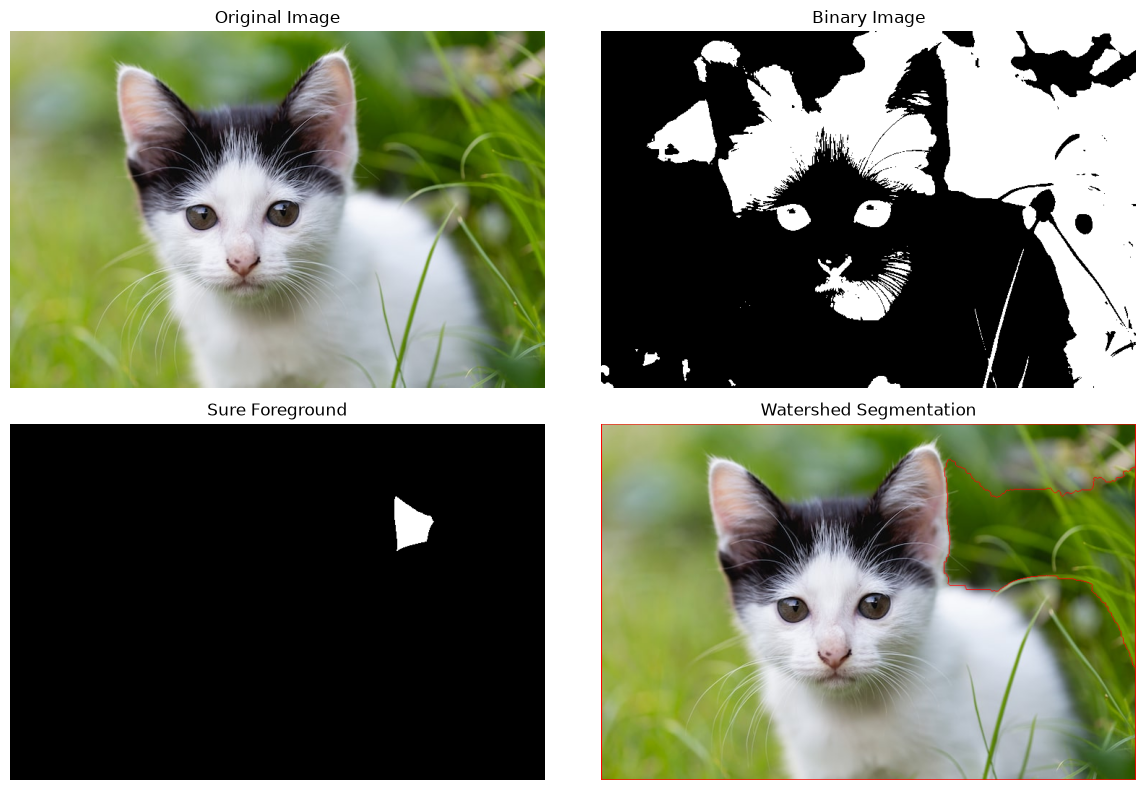

In [3]:
img = cv2.imread("../cat.jpg")

if img is None:
    print("Image not found!")
    exit()


# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


# Apply thresholding
ret, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)


# Remove noise using morphological opening
kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel, iterations=2
)


# Find sure background area
sure_bg = cv2.dilate(opening, kernel, iterations=3)


# Find sure foreground area using distance transform
dist_transform = cv2.distanceTransform(
    opening, cv2.DIST_L2, 5
)

ret, sure_fg = cv2.threshold(
    dist_transform,
    0.7 * dist_transform.max(),
    255, 0
)

sure_fg = np.uint8(sure_fg)


# Find unknown region
unknown = cv2.subtract(sure_bg, sure_fg)


# Label foreground regions
ret, markers = cv2.connectedComponents(sure_fg)


# Add 1 to all labels
markers = markers + 1


# Mark unknown region as 0
markers[unknown == 255] = 0


# Apply Watershed Transformation
markers = cv2.watershed(img, markers)


# Mark watershed boundaries in red
result = img.copy()
result[markers == -1] = [0, 0, 255]


# Display Results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(binary, cmap='gray')
plt.title("Binary Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(sure_fg, cmap='gray')
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

**Purpose:** This cell is intentionally left blank.